
If you add the file locally and you cannot find it this will put it in the place needed to run this, if not its just me that i struggled


In [ ]:
list.files("/")
file.rename(
  "/DeliveryMan_1.2.0.tar.gz",
  "/content/DeliveryMan_1.2.0.tar.gz"
)

[1] "bin"                "bin.usr-is-merged"  "boot"              
 [4] "content"            "datalab"            "dev"               
 [7] "etc"                "home"               "kaggle"            
[10] "lib"                "lib.usr-is-merged"  "lib64"             
[13] "media"              "mnt"                "opt"               
[16] "proc"               "python-apt"         "python-apt.tar.xz" 
[19] "root"               "run"                "sbin"              
[22] "sbin.usr-is-merged" "srv"                "sys"               
[25] "tmp"                "tools"              "usr"               
[28] "var"

Warning message in file.rename("/DeliveryMan_1.2.0.tar.gz", "/content/DeliveryMan_1.2.0.tar.gz"):
“cannot rename file '/DeliveryMan_1.2.0.tar.gz' to '/content/DeliveryMan_1.2.0.tar.gz', reason 'No such file or directory'”


[1] FALSE

In [1]:
R.version.string

install.packages(
    "/content/DeliveryMan_1.2.0.tar",
    repos = NULL,
    type = "source"
)

[1] "R version 4.6.1 (2026-06-24)"

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
library(DeliveryMan)
packageVersion("DeliveryMan")
help(package = "DeliveryMan")

[1] ‘1.2.0’

In [3]:
# Kajsa's part :D

library(DeliveryMan)

?runDeliveryMan

#  shows all possible moves, including new x and y coordinates, its commands, and its costs
possibleMoves <- function(x, y, hroads, vroads) {
    moves <- list()
    maxX <- nrow(hroads) + 1    # +1 because we count roads not stops
    maxY <- ncol(vroads) + 1

    # move left
    if (x > 1) {
        moves[[length(moves) + 1]] <- list(    # add new move at the end of the list
            x = x - 1,
            y = y,
            move = 4,
            cost = hroads[x - 1, y]    # the value becomes the cost of moving left
        )
    }

    # move right
    if (x < maxX) {
        moves[[length(moves) + 1]] <- list(
            x = x + 1,
            y = y,
            move = 6,
            cost = hroads[x, y]
        )
    }

    # move up
    if (y < maxY) {
        moves[[length(moves) + 1]] <- list(
            x = x,
            y = y + 1,
            move = 8,
            cost = vroads[x, y]
        )
    }

    # move down
    if (y > 1) {
        moves[[length(moves) + 1]] <- list(
            x = x,
            y = y - 1,
            move = 2,
            cost = vroads[x, y - 1]
        )
    }

    return(moves)
}

aStar <- function(roads, startX, startY, targetX, targetY)
{
    g = 0 # i tried defining this with the start node, doesnt work

    # Reference of Manhattan distance based on:
    # https://www.geeksforgeeks.org/data-science/manhattan-distance/
    h = abs(startX - targetX) + abs(startY - targetY)

    f = g + h # will help us calculate the route


    # we check if we are where we wanted to be
    #(just like in leetcode problems, to take account of all posibilities)
    if (startX == targetX & startY ==targetY){
      return(5) # why? well, because 5 is to stop, and the delivery man deserves a bit of rest sometimes
    }

    # first_move = NA we dont have yet our first movement (i can just add it into the list)
    # we need to declare each of them as what they represent for the alg to know what we are talking about
    startnode <- list(x =startX ,y = startY ,g = g,h = h,f = f,first_move = NA)

    frontier <- list(startnode)

    # For having control over the ones we have been in already
    explored <- list()

    while (length(frontier) != 0) {
      # based it from here to get the sapply
      # https://r-coder.com/sapply-function-r/
      all_f_values = sapply(frontier, function(s) s$f)
      pos = which.min(all_f_values) # this is our index

      currentnode = frontier[[pos]] # thank you for the hint

      explored[[length(explored) + 1]] = currentnode # to add it into our explored list

      # this is the one we will be, we dont want to see it
      frontier = frontier[-pos]

      # we just check if is our target
      if (currentnode$x == targetX && currentnode$y == targetY) {
          return(currentnode$first_move) # we transform our first move to what the current node told us
      } else {
        # we pass the information to the cool fun kajsa did :D to see more developments
      posmove = possibleMoves(currentnode$x,currentnode$y, roads$hroads ,roads$vroads)

      for (p in posmove) {
        # we need to calculate all the things that we did before:
        g = currentnode$g + p$cost # i struggled with this
        h = abs(p$x - targetX) + abs(p$y - targetY)
        f = g + h
        if (is.na(currentnode$first_move)) { # like in python :D
          first_move = p$move
        } else {
          first_move= currentnode$first_move
        }

        nextnode <- list( x = p$x,y =p$y,g=g,h=h,f=f,first_move= first_move)
          # to avoid repetition:
          match = sapply(frontier, function(p) p$x == nextnode$x & p$y == nextnode$y )
          match_explored = sapply(explored,function(p) p$x == nextnode$x & p$y == nextnode$y)
          if (!any(match_explored)) {
          # we get if they match or not, so we dont make it suboptimal
          if (!any(match)) {
          frontier[[length(frontier) + 1]] = nextnode # i had to do a deep investigation, why it affects the positioning of "="
          # because i would just use append() + this is where the "movement" happens
          } else {
          repeated = which(match)

          if (nextnode$g < frontier[[repeated]]$g) { # we compare the nextnode which the one that is repeated (to find cheaper path)
            frontier[[repeated]] = nextnode # we delete the repeated one for a cheaper one

# the parade of brackets
                }
              }
            }
          }
        }
      }
    }


# Ana's part: choose the target and connect it to A*
chooseTarget <- function(car, packages) {
    # If the car has a package, go to its delivery address
    if (car$load != 0) {
        target <- packages[car$load, c(3, 4)]
        return(target)
    }

    # Find all packages that are still waiting to be picked up
    availablePackages <- which(packages[, 5] == 0)

    # Calculate the distance from the car to every available package
    distances <- abs(packages[availablePackages, 1] - car$x) +
                 abs(packages[availablePackages, 2] - car$y)

    # Choose the nearest package
    bestPackage <- availablePackages[which.min(distances)]
    target <- packages[bestPackage, c(1, 2)]

    return(target)
}

myFunction <- function(roads, car, packages) {
    target <- chooseTarget(car, packages)

    car$mem$goal <- target
    car$nextMove <- aStar(
        roads,
        car$x,
        car$y,
        target[1],
        target[2]
    )

    return(car)
}

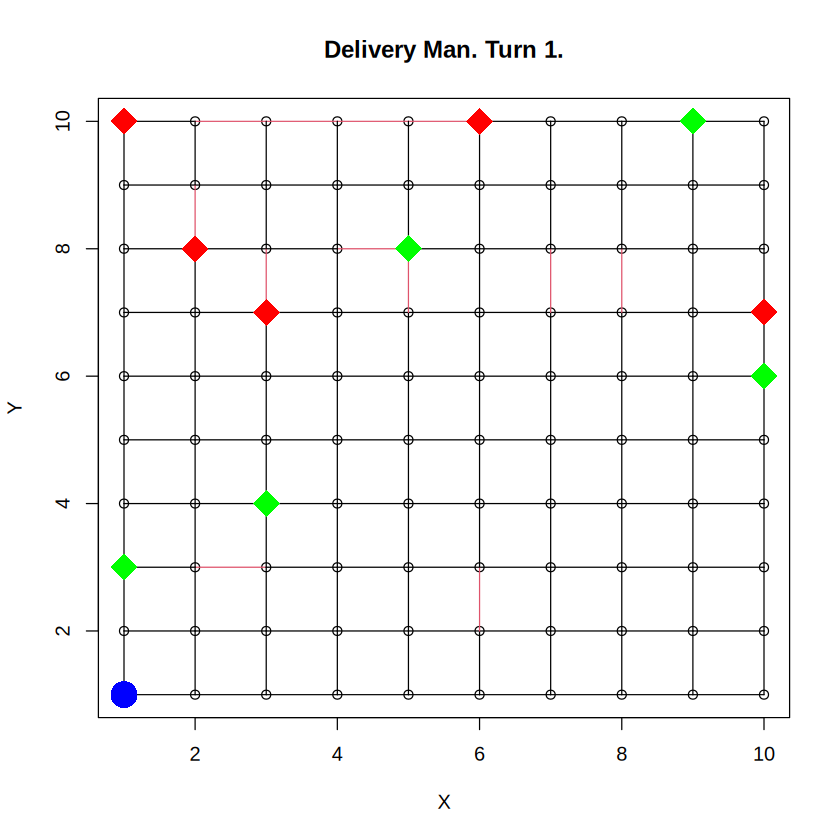

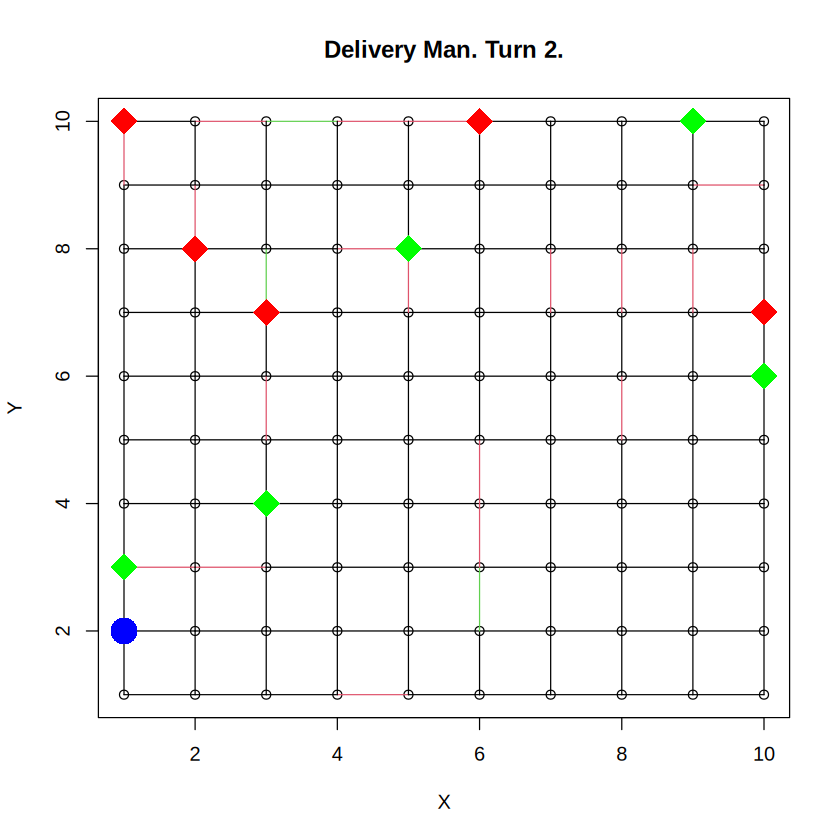

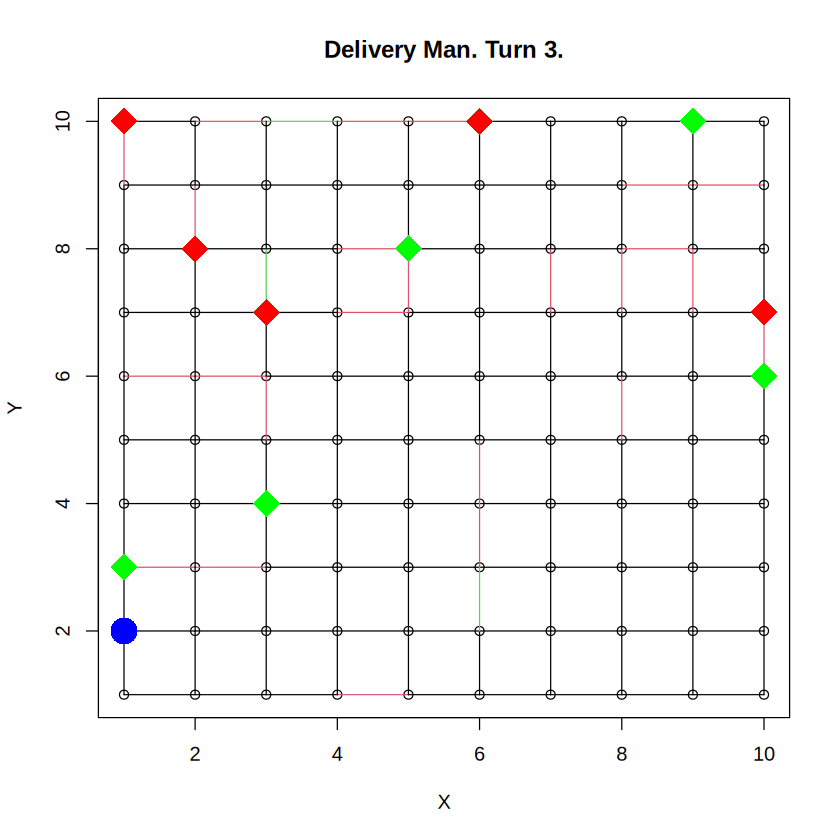

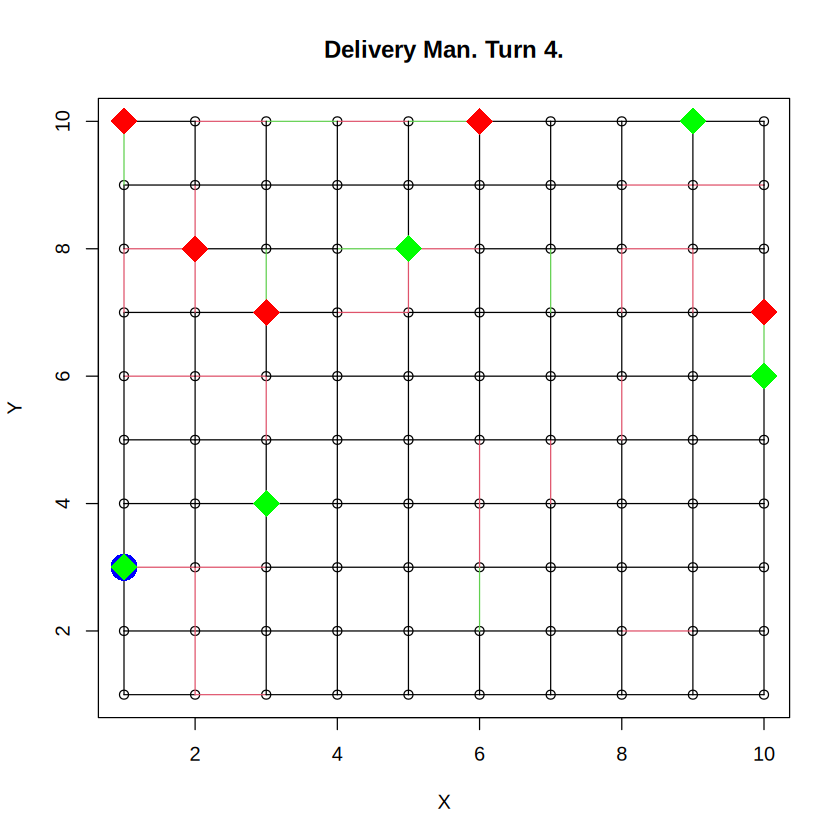

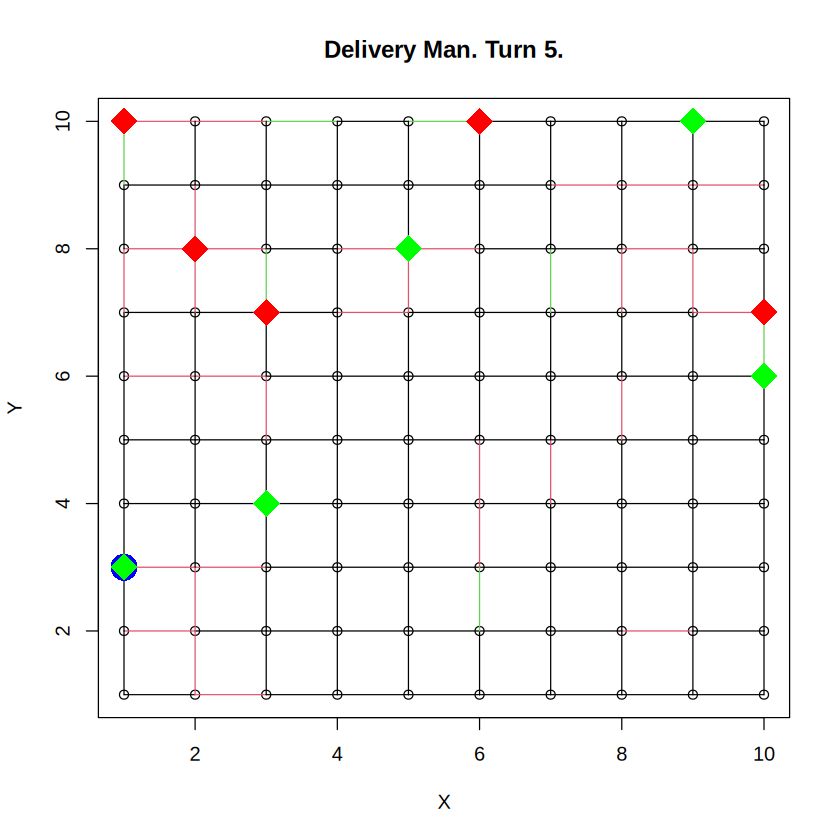

...

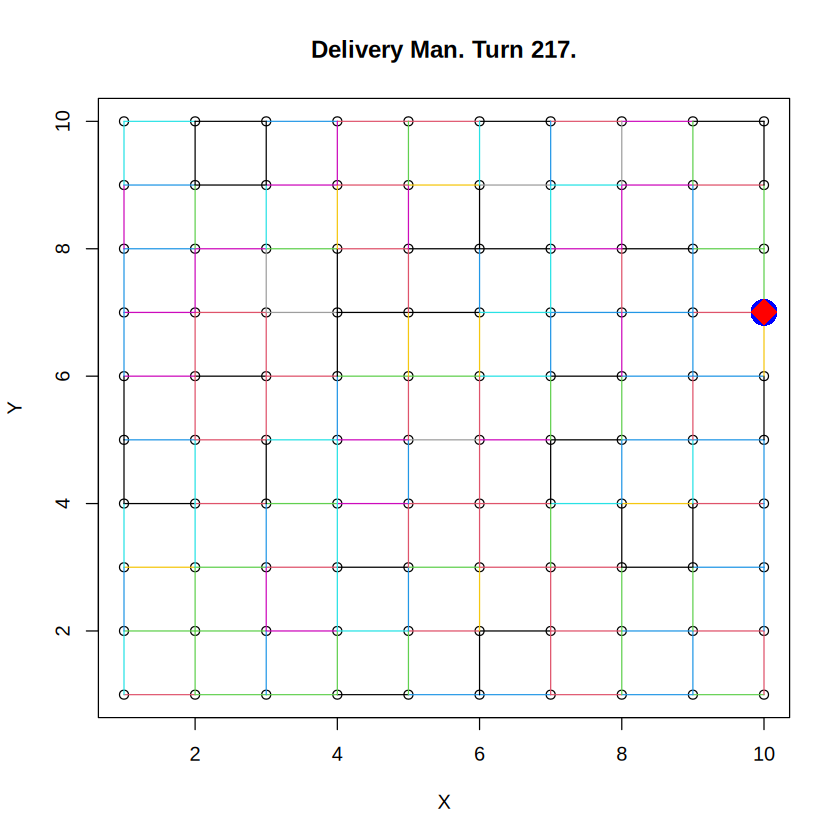

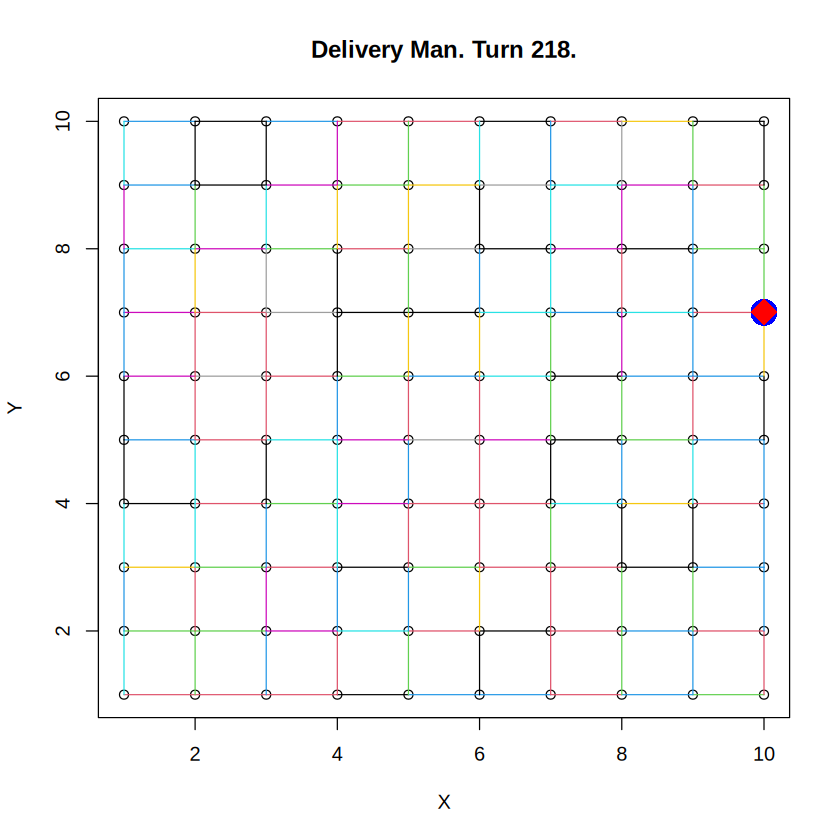

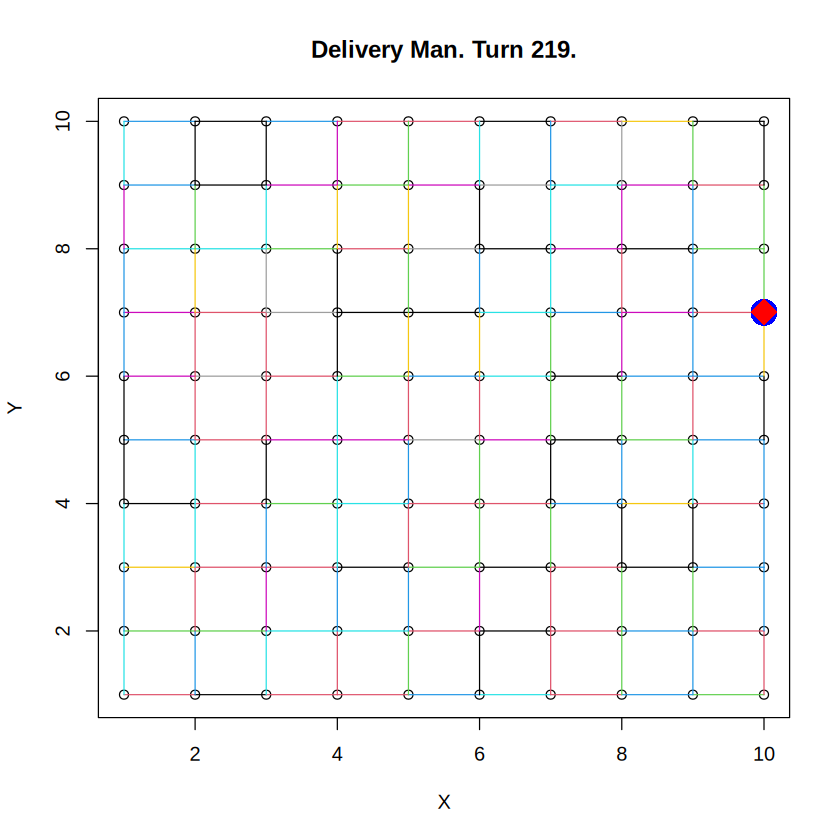

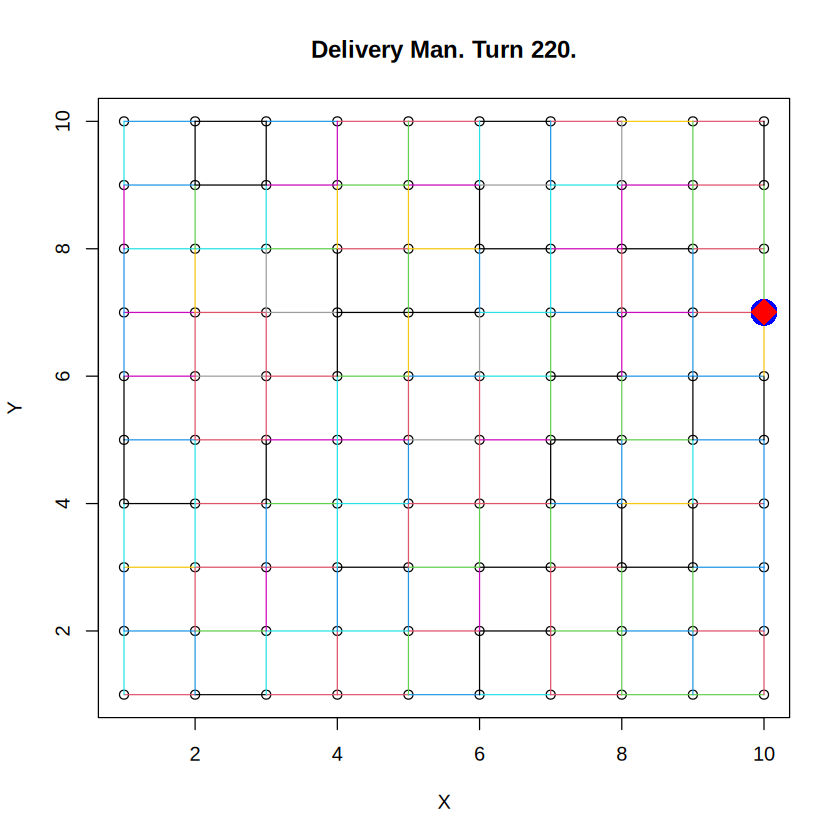

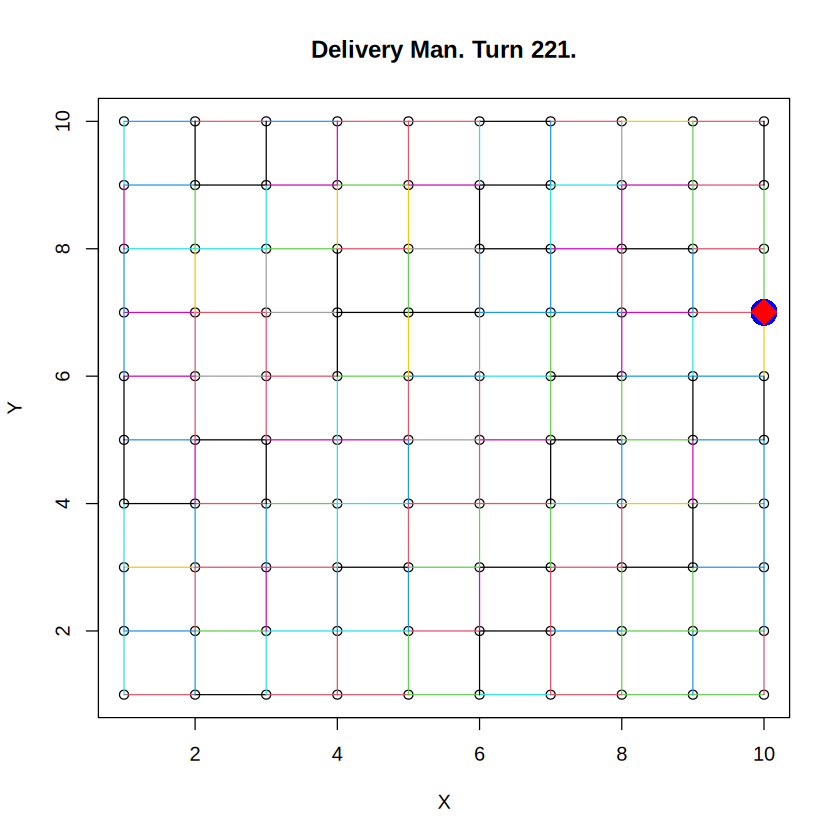


Congratulations! You suceeded in 222 turns!

[1] 222

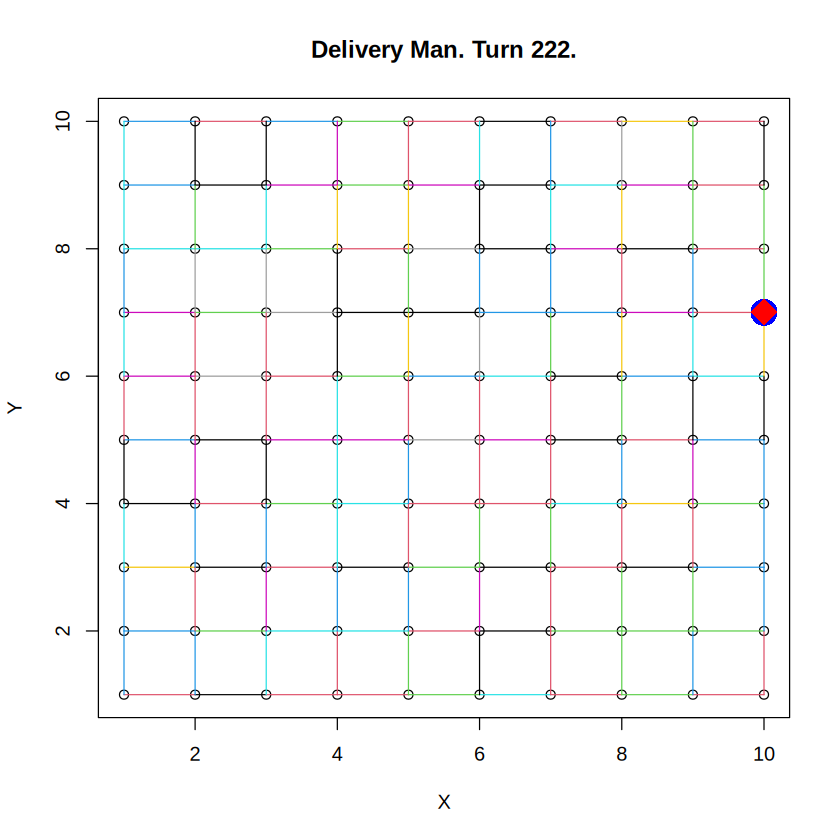

In [ ]:
set.seed(67)

runDeliveryMan(
    myFunction,
    doPlot = TRUE,
    pause = 0.1
)

In [7]:
testDM(
    myFunction,
    verbose = 1,
    n = 500,
    seed = 21
)


Mean: 171.79
Std Dev: 37.54914
Time taken: 202.239 seconds.

[1] 171.79

# Baseline

This is the non edited implementation
which takes 215 turns in order to achieve its goal.

Our objective is to reduce it to an avg. of 180 turns

In [ ]:
set.seed(67)
runDeliveryMan(basicDM)

In [ ]:
basicDM